In [18]:
from pathlib import Path

import torch
import torch.nn as nn
from torchinfo import summary

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.hybrid_model_definition import create_hybrid_model
from src.dataset import create_dataloaders

## Hybrid CNN–Transformer Model

This model combines a **Convolutional Neural Network (CNN)** with a **transformer encoder**, creating a hybrid architecture that uses the strengths of both approaches.

The first two convolutional blocks are taken from the previously trained CNN model and used as a **transfer learning feature extractor**. These layers extract low- and mid-level spatial features from the input geospatial data. Their parameters are frozen during training, so the pretrained CNN features are retained and are not updated.

The resulting feature maps are then converted into a sequence of spatial tokens and passed to a **transformer encoder**. The Transformer learns relationships between features at different spatial locations using self-attention. Finally, the transformed features are aggregated and passed to a classification layer.

In summary:

**Input → pretrained/frozen CNN → spatial tokens → Transformer Encoder → classifier**

This allows the model to reuse the feature-extraction capabilities of the existing CNN while giving the Transformer the task of learning higher-level relationships between spatial regions. We only took the first two CNN blocks from the original model to leave some work to the transformer part of the architecture.


## Set up the hybrid model

In [5]:
img_size = 64
batch_size = 32
lr = 0.001
epochs = 20 
num_classes = 2 # number of classes in the dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device used is {device}")

models_dir = Path("./models")

Device used is cuda


In [6]:
train_loader, val_loader, test_loader = create_dataloaders(batch_size)

model = create_hybrid_model(num_classes = num_classes).to(device)

In [10]:
summary(
    model,
    input_size=(32, 3, 64, 64),
    col_names=["input_size", "output_size", "num_params", "trainable"]
)

Layer (type:depth-idx)                        Input Shape               Output Shape              Param #                   Trainable
CNNTransformer                                [32, 3, 64, 64]           [32, 2]                   --                        Partial
├─Sequential: 1-1                             [32, 3, 64, 64]           [32, 32, 16, 16]          --                        False
│    └─Conv2d: 2-1                            [32, 3, 64, 64]           [32, 16, 64, 64]          (448)                     False
│    └─BatchNorm2d: 2-2                       [32, 16, 64, 64]          [32, 16, 64, 64]          (32)                      False
│    └─ReLU: 2-3                              [32, 16, 64, 64]          [32, 16, 64, 64]          --                        --
│    └─MaxPool2d: 2-4                         [32, 16, 64, 64]          [32, 16, 32, 32]          --                        --
│    └─Conv2d: 2-5                            [32, 16, 32, 32]          [32, 32, 32, 32]  

### Train the model

In [11]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3
)

In [14]:
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(epochs):

    # --------------------------------------------------
    # Training
    # --------------------------------------------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # --------------------------------------------------
    # Validation
    # --------------------------------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # --------------------------------------------------
    # Store history
    # --------------------------------------------------
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)


    print(
        f"Epoch {epoch + 1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/20 | Train Loss: 0.0115 | Train Acc: 0.9964 | Val Loss: 0.0097 | Val Acc: 0.9978
Epoch  2/20 | Train Loss: 0.0187 | Train Acc: 0.9931 | Val Loss: 0.0065 | Val Acc: 0.9978
Epoch  3/20 | Train Loss: 0.0094 | Train Acc: 0.9971 | Val Loss: 0.0148 | Val Acc: 0.9967
Epoch  4/20 | Train Loss: 0.0086 | Train Acc: 0.9979 | Val Loss: 0.0115 | Val Acc: 0.9967
Epoch  5/20 | Train Loss: 0.0072 | Train Acc: 0.9976 | Val Loss: 0.0089 | Val Acc: 0.9978
Epoch  6/20 | Train Loss: 0.0083 | Train Acc: 0.9976 | Val Loss: 0.0031 | Val Acc: 0.9989
Epoch  7/20 | Train Loss: 0.0097 | Train Acc: 0.9971 | Val Loss: 0.0032 | Val Acc: 0.9989
Epoch  8/20 | Train Loss: 0.0094 | Train Acc: 0.9971 | Val Loss: 0.0056 | Val Acc: 0.9978
Epoch  9/20 | Train Loss: 0.0045 | Train Acc: 0.9988 | Val Loss: 0.0021 | Val Acc: 0.9989
Epoch 10/20 | Train Loss: 0.0039 | Train Acc: 0.9988 | Val Loss: 0.0182 | Val Acc: 0.9956
Epoch 11/20 | Train Loss: 0.0047 | Train Acc: 0.9983 | Val Loss: 0.0044 | Val Acc: 0.9989
Epoch 12/2

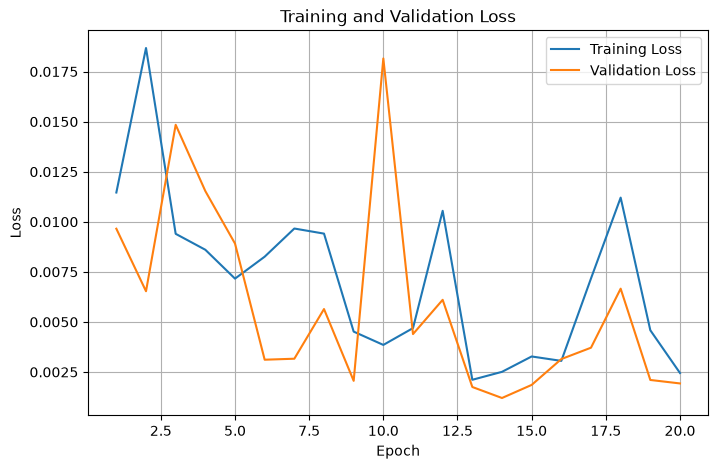

In [16]:
epochs_range = range(1, epochs + 1)

# Loss
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, history["train_loss"], label="Training Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
torch.save(
    model.state_dict(),
    models_dir / "hybrid.pth"
)

### Evaluate on the test set

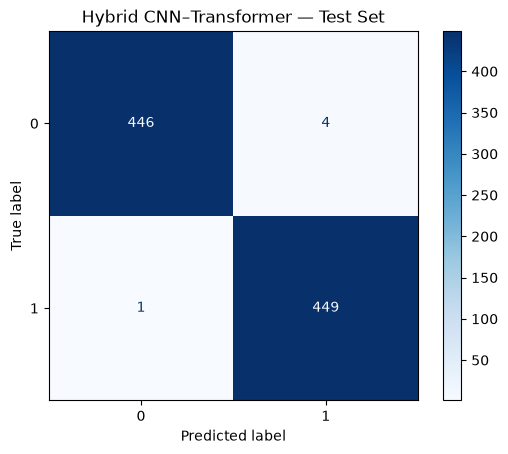

In [19]:
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())


# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues")

plt.title("Hybrid CNN–Transformer — Test Set")
plt.show()